# 📱 Unveiling the Android App Market
### Google Play Store Analysis
**Author:** saurabhshukla  |  **Email:** saurabhshuklant@gmail.com

**Task 4 – Data analysis**

### Objective
Take the messy, real-world Google Play Store data, clean it, and answer practical questions: which categories are crowded, how are apps rated, does size matter for installs, how is pricing structured, and what do users feel about the apps (sentiment analysis). The notebook ends with three data-driven takeaways for a developer planning a new app.

### Tech stack
Python, pandas, numpy, matplotlib, seaborn, plotly, VADER (sentiment)

### Datasets
- `googleplaystore.csv` – ~10,800 app listings (category, rating, reviews, size, installs, price, ...). The latest update date in the file is August 2018, so this is a snapshot from that time and not today's store.
- `googleplaystore_user_reviews.csv` – user reviews with the app name. Used only in the sentiment section (section 8).

### Outline
1. Load  →  2. Clean  →  3. Categories  →  4. Ratings  →  5. Size vs installs  →  6. Pricing and revenue  →  7. Interactive charts  →  8. Sentiment analysis  →  9. Conclusion

## Setup
`plotly` and `vaderSentiment` are not part of a default Anaconda install. If they are missing on your machine, run the next cell once (and restart the kernel if the import still fails).

In [ ]:
%pip install -q plotly vaderSentiment

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", None)

## 1. Loading the apps data

In [2]:
apps_raw = pd.read_csv("googleplaystore.csv")
print("Shape:", apps_raw.shape)
apps_raw.head()

Shape: (10841, 13)

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [3]:
apps_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  str    
 1   Category        10841 non-null  str    
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  str    
 4   Size            10841 non-null  str    
 5   Installs        10841 non-null  str    
 6   Type            10840 non-null  str    
 7   Price           10841 non-null  str    
 8   Content Rating  10840 non-null  str    
 9   Genres          10841 non-null  str    
 10  Last Updated    10841 non-null  str    
 11  Current Ver     10833 non-null  str    
 12  Android Ver     10838 non-null  str    
dtypes: float64(1), str(12)
memory usage: 1.1 MB

In [4]:
nulls = apps_raw.isnull().sum()
nulls[nulls > 0]

Rating            1474
Type                 1
Content Rating       1
Current Ver          8
Android Ver          3
dtype: int64

**First impressions**
- 10,841 rows and 13 columns. Almost every column is stored as text, including the ones that should be numbers: `Reviews`, `Size`, `Installs` and `Price`. Only `Rating` is numeric. So nothing numeric can be analysed until these are fixed.
- `Rating` has 1,474 missing values (about 14%). Every other column has at most a handful of nulls.
- Values like `10,000+`, `19M`, `$4.99` and `Varies with device` all need to be parsed into real numbers.

## 2. Data cleaning
### 2.1 A broken row

In [5]:
# Valid categories are written like ART_AND_DESIGN. Anything else is suspicious.
valid_cat = apps_raw["Category"].str.match(r"^[A-Z_]+$", na=False)
apps_raw[~valid_cat]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10472,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.0,3.0M,"1,000+",Free,0,Everyone,NaN,"February 11, 2018",1.0.19,4.0 and up,NaN


Row 10472 is misaligned: its values are shifted one column to the left, so `Category` contains `1.9` (which is actually the rating) and `Rating` is empty. Instead of guessing how to realign it, I'm dropping this one row – one app out of ten thousand does not change any conclusion.

In [6]:
# Dropping the broken row, then working on a copy so apps_raw stays untouched
apps = apps_raw[valid_cat].copy()
print("Rows after removing the broken row:", len(apps))

Rows after removing the broken row: 10840

### 2.2 Fixing data types

In [7]:
# --- Reviews: text -> integer
apps["Reviews"] = pd.to_numeric(apps["Reviews"], errors="coerce").astype("int64")

# --- Installs: "10,000+" -> 10000   (note: this is a lower bound, not an exact count)
apps["Installs"] = apps["Installs"].str.replace("[+,]", "", regex=True).astype("int64")

# --- Price: "$4.99" -> 4.99
apps["Price"] = apps["Price"].str.replace("$", "", regex=False).astype(float)

# --- Size: "19M" / "201k" -> megabytes. "Varies with device" has no real size, so NaN
def size_to_mb(value):
    value = str(value).strip()
    if value.endswith("M"):
        return float(value[:-1])
    if value.endswith("k"):
        return float(value[:-1]) / 1024
    return np.nan

apps["Size_MB"] = apps["Size"].apply(size_to_mb)

# --- Last Updated: text -> datetime
apps["Last Updated"] = pd.to_datetime(apps["Last Updated"], format="%B %d, %Y", errors="coerce")

apps[["Reviews", "Installs", "Price", "Size_MB", "Last Updated"]].dtypes

Reviews                  int64
Installs                 int64
Price                  float64
Size_MB                float64
Last Updated    datetime64[us]
dtype: object

What I did and why:
- **Installs** `10,000+` → `10000`. Important: this is a *lower bound* of a bucket, not an exact count, so every install figure later on is approximate.
- **Price** `$4.99` → `4.99`.
- **Size** → megabytes, converting `k` to MB. `Varies with device` has no real size, so it becomes `NaN` instead of a made-up number.
- **Reviews** → integer, **Last Updated** → datetime.

### 2.3 Handling nulls

In [8]:
# One app has no "Type". Its price tells us what it is: price 0 -> Free, otherwise Paid
missing_type = apps["Type"].isnull()
print("Apps with missing Type:", missing_type.sum())
apps.loc[missing_type, "Type"] = np.where(apps.loc[missing_type, "Price"] == 0, "Free", "Paid")

# Ratings: look at who is missing before deciding what to do
no_rating = apps["Rating"].isnull()
print(f"Apps without a rating: {no_rating.sum()} ({no_rating.mean():.1%})")
print("Median installs - rated apps    :", f"{apps.loc[~no_rating, 'Installs'].median():,.0f}")
print("Median installs - not rated apps:", f"{apps.loc[no_rating, 'Installs'].median():,.0f}")

Apps with missing Type: 1
Apps without a rating: 1474 (13.6%)
Median installs - rated apps    : 500,000
Median installs - not rated apps: 100

**Decisions**
- The single app with no `Type` is filled using its price: price 0 means Free.
- **Ratings are not imputed.** The missing-rating apps are not a random sample: their median installs is just 100, against 500,000 for apps that have a rating. They are basically brand-new or unused apps that nobody has rated yet. Filling them with the average would invent ratings for apps no one has reviewed, so I leave them out only of the rating analysis and keep them everywhere else.
- `Current Ver`, `Android Ver` and `Content Rating` have a few nulls but are not used in the analysis, so I'm leaving them alone.

### 2.4 Removing duplicates

In [9]:
# Exact duplicates first, then the same app listed more than once.
# For repeated apps I keep the row with the most reviews (the most up-to-date one).
print("Exact duplicate rows      :", apps.duplicated().sum())
apps = apps.drop_duplicates()

print("Apps still listed twice   :", apps["App"].duplicated().sum())
apps = (apps.sort_values("Reviews", ascending=False)
            .drop_duplicates(subset="App", keep="first")
            .sort_index()
            .reset_index(drop=True))

print("Final number of unique apps:", len(apps))

Exact duplicate rows      : 483
Apps still listed twice   : 698
Final number of unique apps: 9659

There are two kinds of duplicates here. 483 rows were exact copies. After removing those, 698 apps were still listed more than once with slightly different numbers (usually the review count). For those I keep the row with the most reviews, which is the most recent snapshot. Without this step, popular apps would be counted two or three times and distort every average. **Final dataset: 9,659 unique apps.**

In [10]:
print("Remaining nulls in key columns:")
print(apps[["App", "Category", "Reviews", "Installs", "Type", "Price"]].isnull().sum().to_string())
print("\nCleaned data types:")
print(apps[["Rating", "Reviews", "Installs", "Price", "Size_MB"]].dtypes.to_string())
apps.head()

Remaining nulls in key columns:
App         0
Category    0
Reviews     0
Installs    0
Type        0
Price       0

Cleaned data types:
Rating      float64
Reviews       int64
Installs      int64
Price       float64
Size_MB     float64

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver,Size_MB
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,10000,Free,0.0,Everyone,Art & Design,2018-01-07,1.0.0,4.0.3 and up,19.0
1,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,5000000,Free,0.0,Everyone,Art & Design,2018-08-01,1.2.4,4.0.3 and up,8.7
2,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,50000000,Free,0.0,Teen,Art & Design,2018-06-08,Varies with device,4.2 and up,25.0
3,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,100000,Free,0.0,Everyone,Art & Design;Creativity,2018-06-20,1.1,4.4 and up,2.8
4,Paper flowers instructions,ART_AND_DESIGN,4.4,167,5.6M,50000,Free,0.0,Everyone,Art & Design,2017-03-26,1.0,2.3 and up,5.6


## 3. Category analysis
How are apps spread across categories, and which ones are saturated?

Top 5 categories hold 46.2% of all apps

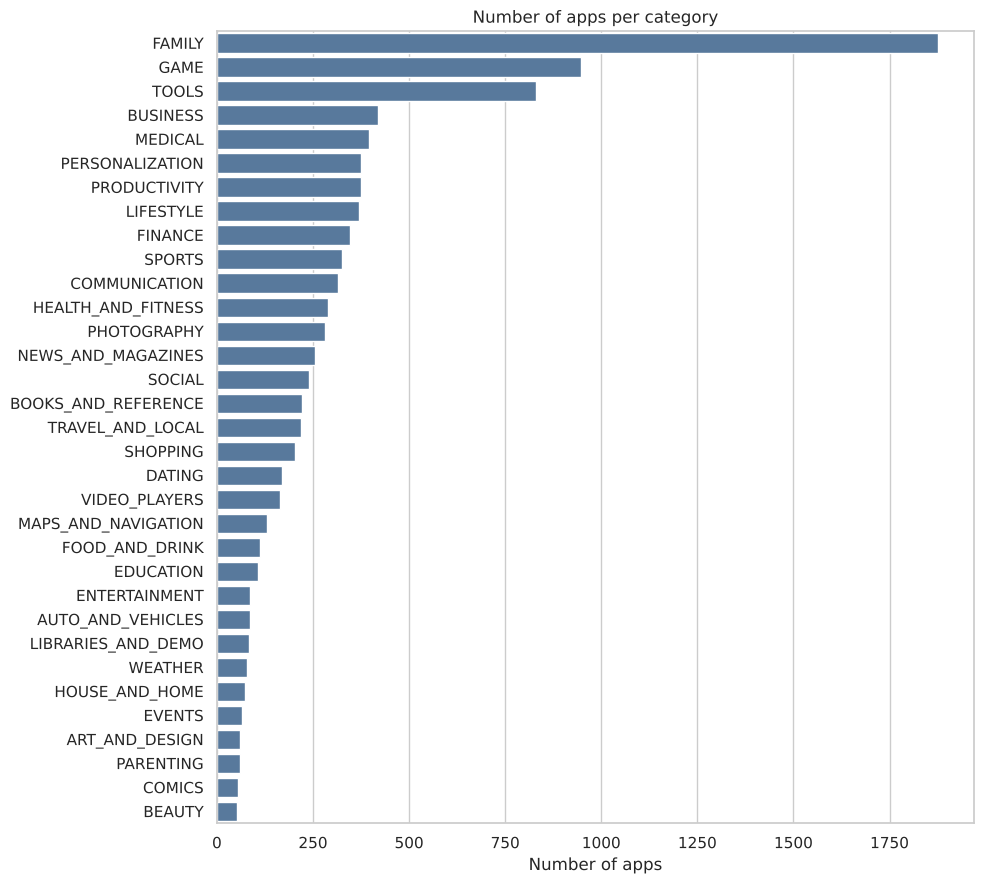

Category
FAMILY             1876
GAME                946
TOOLS               829
BUSINESS            420
MEDICAL             395
PERSONALIZATION     376
PRODUCTIVITY        374
LIFESTYLE           369
FINANCE             345
SPORTS              325
Name: count, dtype: int64

In [11]:
cat_counts = apps["Category"].value_counts()

plt.figure(figsize=(10, 9))
sns.barplot(x=cat_counts.values, y=cat_counts.index, color="#4c78a8")
plt.title("Number of apps per category")
plt.xlabel("Number of apps")
plt.ylabel("")
plt.tight_layout()
plt.show()

top5_share = cat_counts.head(5).sum() / cat_counts.sum()
print(f"Top 5 categories hold {top5_share:.1%} of all apps")
cat_counts.head(10)

In [12]:
# Number of apps alone doesn't tell the whole story. Putting it next to demand (installs)
cat_summary = (apps.groupby("Category")
                    .agg(apps=("App", "count"),
                         median_installs=("Installs", "median"),
                         total_installs=("Installs", "sum"),
                         avg_rating=("Rating", "mean"))
                    .sort_values("apps", ascending=False))
cat_summary["installs_per_app"] = cat_summary["total_installs"] / cat_summary["apps"]
cat_summary.head(10)

,apps,median_installs,total_installs,avg_rating,installs_per_app
Category,,,,,
FAMILY,1876,50000.0,6226542505,4.183767,3.319053e+06
GAME,946,1000000.0,13457924415,4.244605,1.422614e+07
TOOLS,829,50000.0,8102771915,4.040278,9.774152e+06
BUSINESS,420,1000.0,697164865,4.098479,1.659916e+06
MEDICAL,395,1000.0,38293077,4.165862,9.694450e+04
PERSONALIZATION,376,10000.0,1532494782,4.332215,4.075784e+06
PRODUCTIVITY,374,100000.0,5793091369,4.183389,1.548955e+07
LIFESTYLE,369,10000.0,503823539,4.093355,1.365375e+06
FINANCE,345,10000.0,455348734,4.115563,1.319851e+06


In [13]:
cat_summary.sort_values("installs_per_app", ascending=False)[["apps", "median_installs", "installs_per_app"]].head(8)

,apps,median_installs,installs_per_app
Category,,,
COMMUNICATION,315,100000.0,3.504215e+07
VIDEO_PLAYERS,164,1000000.0,2.397502e+07
SOCIAL,239,100000.0,2.296179e+07
PHOTOGRAPHY,281,1000000.0,1.657704e+07
PRODUCTIVITY,374,100000.0,1.548955e+07
GAME,946,1000000.0,1.422614e+07
TRAVEL_AND_LOCAL,219,100000.0,1.321866e+07
ENTERTAINMENT,86,1000000.0,1.144953e+07


In [14]:
cat_demand = cat_summary[cat_summary["apps"] >= 100].sort_values("median_installs", ascending=False)
print("Highest median installs (categories with 100+ apps):")
print(cat_demand["median_installs"].head(5).to_string())
print("\nLowest median installs:")
print(cat_demand["median_installs"].tail(5).to_string())

Highest median installs (categories with 100+ apps):
Category
GAME             1000000.0
EDUCATION        1000000.0
PHOTOGRAPHY      1000000.0
SHOPPING         1000000.0
VIDEO_PLAYERS    1000000.0

Lowest median installs:
Category
LIFESTYLE              10000.0
DATING                 10000.0
BOOKS_AND_REFERENCE    10000.0
BUSINESS                1000.0
MEDICAL                 1000.0

**Insights**
- The market is concentrated: **FAMILY (1,876), GAME (946) and TOOLS (829)** are the biggest categories, and the top five categories hold about 46% of all apps. FAMILY is a broad catch-all category, so it is naturally large.
- "Saturated" should mean many apps *relative to demand*, and the table shows that supply and demand do not line up:
  - **BUSINESS (420 apps) and MEDICAL (395 apps)** are crowded but have a median of only **1,000 installs** per app. Lots of supply, little traction for the typical app.
  - **GAME (946 apps)** looks busy too, but its median is 1,000,000 installs. Demand is huge, though very uneven: the average game has ~14 million installs while the median game has 1 million, so a few giants take most of it.
  - **COMMUNICATION, VIDEO_PLAYERS and SOCIAL** have the most installs per app, but that is driven by a handful of giants (think WhatsApp or YouTube), which makes them hard to enter.
- Among categories with 100+ apps, the **highest median installs (1 million)** belong to GAME, EDUCATION, PHOTOGRAPHY, SHOPPING and VIDEO_PLAYERS, and the lowest to BUSINESS and MEDICAL (1,000).

## 4. Ratings analysis

Share of apps rated 4.0 or higher: 76.7%
Share of apps rated below 3.0    : 3.4%

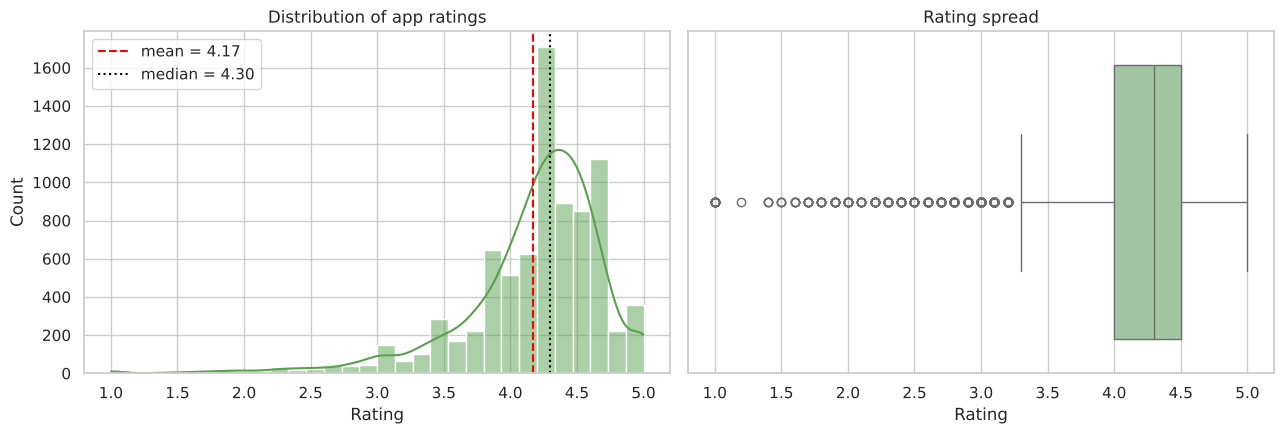

count    8196.000000
mean        4.173267
std         0.536253
min         1.000000
25%         4.000000
50%         4.300000
75%         4.500000
max         5.000000
Name: Rating, dtype: float64

In [15]:
rated = apps.dropna(subset=["Rating"])   # only apps that actually have a rating

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(rated["Rating"], bins=30, kde=True, ax=axes[0], color="#59a14f")
axes[0].set_title("Distribution of app ratings")
axes[0].axvline(rated["Rating"].mean(), color="red", linestyle="--", label=f"mean = {rated['Rating'].mean():.2f}")
axes[0].axvline(rated["Rating"].median(), color="black", linestyle=":", label=f"median = {rated['Rating'].median():.2f}")
axes[0].legend()

sns.boxplot(x=rated["Rating"], ax=axes[1], color="#9ccc9c")
axes[1].set_title("Rating spread")
plt.tight_layout()
plt.show()

print(f"Share of apps rated 4.0 or higher: {(rated['Rating'] >= 4).mean():.1%}")
print(f"Share of apps rated below 3.0    : {(rated['Rating'] < 3).mean():.1%}")
rated["Rating"].describe()

**Insights**
- Ratings pile up on the right: the **mean is 4.17 but the median is 4.30**, and 76.7% of rated apps score 4.0 or more. Only 3.4% are below 3.0.
- The practical meaning: **ratings are inflated.** A 4.0 sounds good, but it is actually the 25th percentile – a quarter of all rated apps are at or below it.
- This analysis covers only apps that have a rating (8,196 of them). Since unrated apps are mostly tiny ones, the picture is of apps that got at least some traction.

Highest: {'EVENTS': 4.44, 'ART_AND_DESIGN': 4.36, 'EDUCATION': 4.35}
Lowest : {'TOOLS': 4.04, 'MAPS_AND_NAVIGATION': 4.04, 'DATING': 3.98}
Gap between best and worst category: 0.46

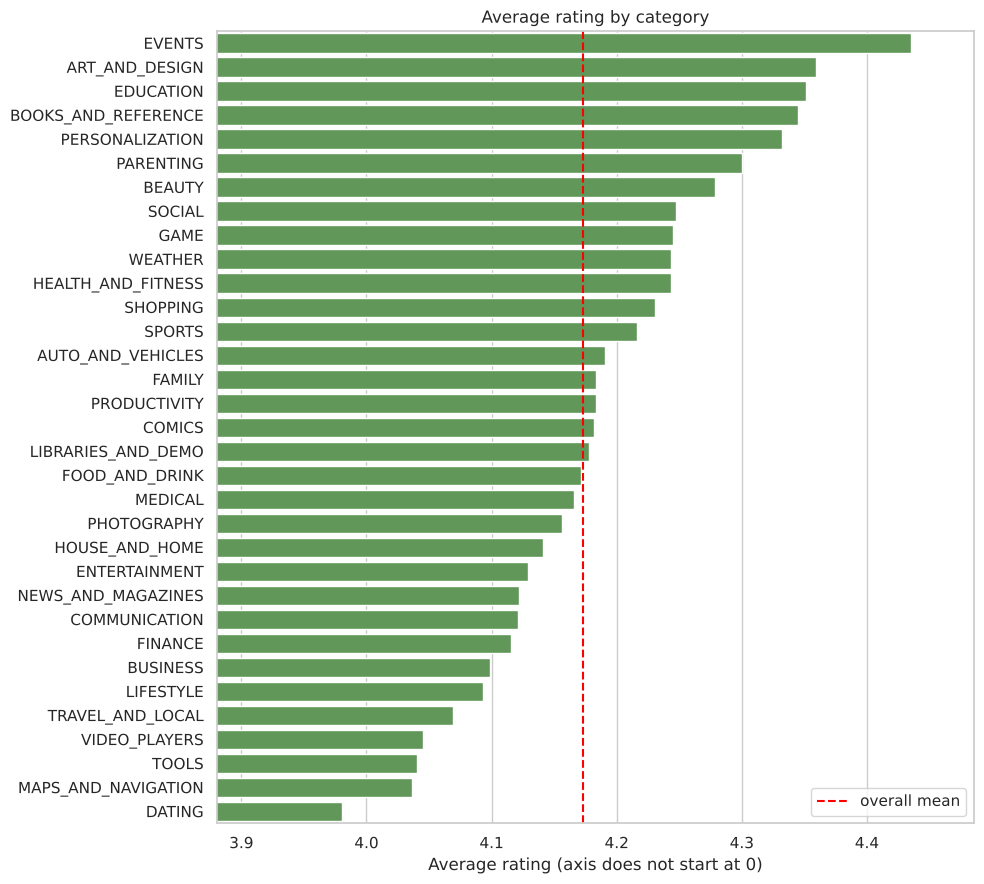

In [16]:
avg_rating = rated.groupby("Category")["Rating"].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 9))
sns.barplot(x=avg_rating.values, y=avg_rating.index, color="#59a14f")
plt.xlim(avg_rating.min() - 0.1, avg_rating.max() + 0.05)   # zoomed in on purpose, see note below
plt.axvline(rated["Rating"].mean(), color="red", linestyle="--", label="overall mean")
plt.title("Average rating by category")
plt.xlabel("Average rating (axis does not start at 0)")
plt.ylabel("")
plt.legend()
plt.tight_layout()
plt.show()

print("Highest:", avg_rating.head(3).round(2).to_dict())
print("Lowest :", avg_rating.tail(3).round(2).to_dict())
print(f"Gap between best and worst category: {avg_rating.max() - avg_rating.min():.2f}")

**Insights**
- The best-rated categories are **EVENTS (4.44), ART_AND_DESIGN (4.36) and EDUCATION (4.35)**. The lowest are **DATING (3.98), TOOLS (4.04) and MAPS_AND_NAVIGATION (4.04)**.
- The whole spread between best and worst is only 0.46 points. The axis in the chart is deliberately zoomed in to make the differences visible, so please read it with that in mind: differences look bigger than they are.
- A possible reading is that users are more demanding where an app has to *work* (navigation, tools, dating) than where it is for enjoyment or learning, but the data cannot prove the reason. Also, smaller categories can swing more from just a few apps.

## 5. Size vs installs

Apps with a known size: 8431
Spearman correlation (rank based): 0.31
Pearson correlation on log(installs): 0.3

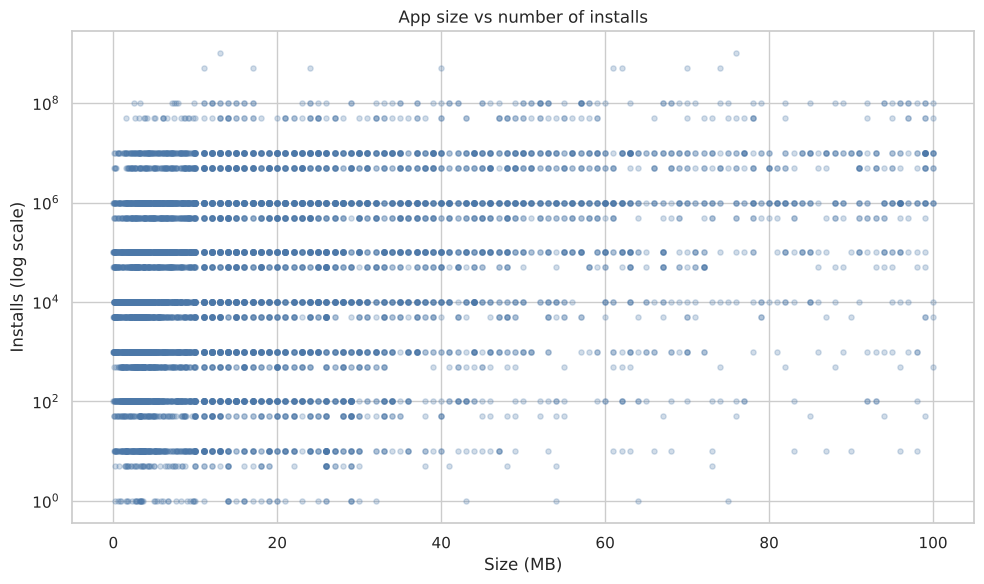

In [17]:
size_df = apps.dropna(subset=["Size_MB"])

plt.figure(figsize=(10, 6))
plt.scatter(size_df["Size_MB"], size_df["Installs"], alpha=0.25, s=14, color="#4c78a8")
plt.yscale("log")   # installs range from 0 to 1 billion, so a log scale is the only way to read it
plt.title("App size vs number of installs")
plt.xlabel("Size (MB)")
plt.ylabel("Installs (log scale)")
plt.tight_layout()
plt.show()

print("Apps with a known size:", len(size_df))
print("Spearman correlation (rank based):", round(size_df["Size_MB"].corr(size_df["Installs"], method="spearman"), 3))
print("Pearson correlation on log(installs):", round(size_df["Size_MB"].corr(np.log10(size_df["Installs"] + 1)), 3))

**Insights**
- Apps with a known size: 8,431 (the "Varies with device" apps have no size and are excluded).
- The relationship is a **weak-to-moderate positive** one: Spearman ≈ 0.31 (rank based, the right choice because installs are extremely skewed) and Pearson ≈ 0.30 on log(installs). So bigger apps tend to have more installs, but there is a lot of scatter and size explains only a small part of it.

In [18]:
size_df = size_df.copy()
size_df["size_bucket"] = pd.cut(size_df["Size_MB"], bins=[0, 5, 15, 30, 60, 100],
                                labels=["<5 MB", "5-15 MB", "15-30 MB", "30-60 MB", "60-100 MB"])
size_df.groupby("size_bucket", observed=True)["Installs"].agg(["count", "median"])

,count,median
size_bucket,,
<5 MB,2317,5000.0
5-15 MB,2494,10000.0
15-30 MB,1719,100000.0
30-60 MB,1301,500000.0
60-100 MB,600,1000000.0


The buckets make the trend clear: median installs rise from **5,000 for apps under 5 MB** to **1,000,000 for apps of 60–100 MB**.

**Careful – this is correlation, not causation.** Large apps are usually games and products from established companies with more content, more features and bigger marketing budgets. Making an app heavier will not bring installs; what the data says is that successful apps tend to be content-rich.

## 6. Pricing analysis

Type
Free    8905
Paid     754
Name: count, dtype: int64

Paid apps: 7.8%
count    754.000000
mean      14.055902
std       58.821000
min        0.990000
25%        1.490000
50%        2.990000
75%        4.990000
max      400.000000
Name: Price, dtype: float64

Paid apps priced above $100: 20

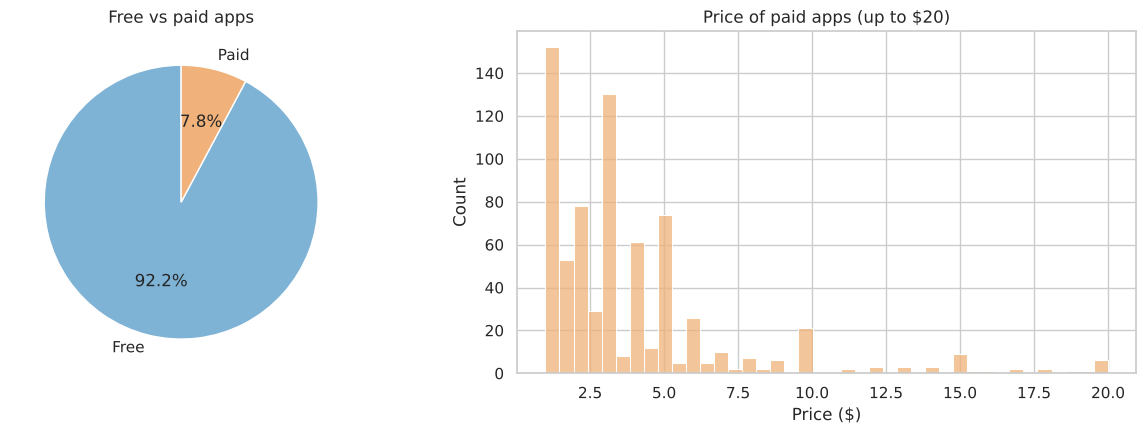

In [19]:
type_counts = apps["Type"].value_counts()
print(type_counts)
print(f"\nPaid apps: {type_counts['Paid'] / type_counts.sum():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].pie(type_counts.values, labels=type_counts.index, autopct="%1.1f%%",
            colors=["#7fb3d5", "#f0b27a"], startangle=90)
axes[0].set_title("Free vs paid apps")

paid = apps[apps["Type"] == "Paid"]
sns.histplot(paid[paid["Price"] <= 20]["Price"], bins=40, ax=axes[1], color="#f0b27a")
axes[1].set_title("Price of paid apps (up to $20)")
axes[1].set_xlabel("Price ($)")
plt.tight_layout()
plt.show()

print(paid["Price"].describe())
print("\nPaid apps priced above $100:", (paid["Price"] > 100).sum())

In [20]:
apps.groupby("Type").agg(apps=("App", "count"),
                          median_installs=("Installs", "median"),
                          avg_rating=("Rating", "mean"),
                          median_reviews=("Reviews", "median"))

,apps,median_installs,avg_rating,median_reviews
Type,,,,
Free,8905,100000.0,4.166223,1379.0
Paid,754,1000.0,4.262126,88.5


**Insights**
- The store is overwhelmingly free: **8,905 free apps (92.2%) against 754 paid (7.8%)**.
- Paid prices are low: the median is **$2.99** and 75% of paid apps cost $4.99 or less. The mean ($14.06) is pulled up by 20 apps priced above $100, which I look at below.
- **Free apps get far more installs**: median 100,000 against 1,000 for paid apps, and far more reviews (median 1,379 vs 88).
- Paid apps have a slightly higher average rating (4.26 vs 4.17). The gap is small, and it likely reflects that people who pay are a self-selected group and fewer of them leave reviews, so I would not read much into it.

In [21]:
paid = apps[apps["Type"] == "Paid"].copy()
paid["price_band"] = pd.cut(paid["Price"], bins=[0, 1, 3, 5, 10, 1000],
                            labels=["up to $1", "$1-3", "$3-5", "$5-10", "above $10"])
paid.groupby("price_band", observed=True).agg(apps=("App", "count"),
                                               median_installs=("Installs", "median"))

,apps,median_installs
price_band,,
up to $1,148,500.0
$1-3,290,1000.0
$3-5,159,5000.0
$5-10,84,1000.0
above $10,73,1000.0


Within paid apps, the **$3–5 band has the highest median installs (5,000)**, against 500 for apps up to $1 and about 1,000 for the other bands. So the cheapest apps are not the most downloaded. The sample per band is small (73 to 290 apps), so this is a hint and not a rule.

### Revenue estimate
There is no revenue column, so I estimate it as **price × installs**. Two honest caveats: installs is a lower bound, and this ignores Google's commission, refunds and discounts. Also, it covers only the upfront price, **not ads or in-app purchases**, which is how most free apps earn. Treat the numbers as an order of magnitude.

In [22]:
# Rough revenue estimate = price x installs.
# Caveats: Installs is a lower bound (10,000+ means "at least 10,000"), and this ignores
# Google's commission, refunds and discounts. So it is an order of magnitude, not an exact figure.
apps["Revenue_Est"] = apps["Price"] * apps["Installs"]

top_paid = (apps[apps["Type"] == "Paid"]
            .sort_values("Revenue_Est", ascending=False)
            .head(8)[["App", "Category", "Price", "Installs", "Revenue_Est"]])
top_paid

,App,Category,Price,Installs,Revenue_Est
1617,Minecraft,FAMILY,6.99,10000000,69900000.0
4259,I am rich,LIFESTYLE,399.99,100000,39999000.0
4263,I Am Rich Premium,FINANCE,399.99,50000,19999500.0
3048,Hitman Sniper,GAME,0.99,10000000,9900000.0
6262,Grand Theft Auto: San Andreas,GAME,6.99,1000000,6990000.0
2104,Facetune - For Free,PHOTOGRAPHY,5.99,1000000,5990000.0
4471,Sleep as Android Unlock,LIFESTYLE,5.99,1000000,5990000.0
7626,DraStic DS Emulator,GAME,4.99,1000000,4990000.0


The top of the list is a good warning about outliers: besides real products like **Minecraft** (≈ $70M estimated) there are the **"I am rich"** apps, novelty apps priced around $400 that do nothing. Let me look at everything priced above $100 separately.

In [23]:
# The "I am rich" type apps are novelty/joke apps priced around $400. Their numbers would
# dominate the picture, so I'm looking at them separately and excluding anything above $100.
novelty = apps[(apps["Type"] == "Paid") & (apps["Price"] > 100)]
print("Apps priced above $100:", len(novelty))
print(f"Their combined estimated revenue: ${novelty['Revenue_Est'].sum() / 1e6:,.1f} million")
print("Their median installs:", f"{novelty['Installs'].median():,.0f}")
novelty[["App", "Price", "Installs"]].sort_values("Installs", ascending=False).head(5)

Apps priced above $100: 20
Their combined estimated revenue: $86.5 million
Their median installs: 3,000

,App,Price,Installs
4259,I am rich,399.99,100000
4263,I Am Rich Premium,399.99,50000
3315,I'm Rich - Trump Edition,400.00,10000
3311,💎 I'm rich,399.99,10000
4262,I am rich VIP,299.99,10000


20 novelty apps above $100 add up to an estimated $86.5M, but their median install count is only 3,000, so their figures come from a tiny number of buyers and would badly distort the category chart (they inflate LIFESTYLE and FINANCE). I'm excluding them from the revenue by category below.

Total estimated revenue of paid apps (price <= $100): $204.6 million

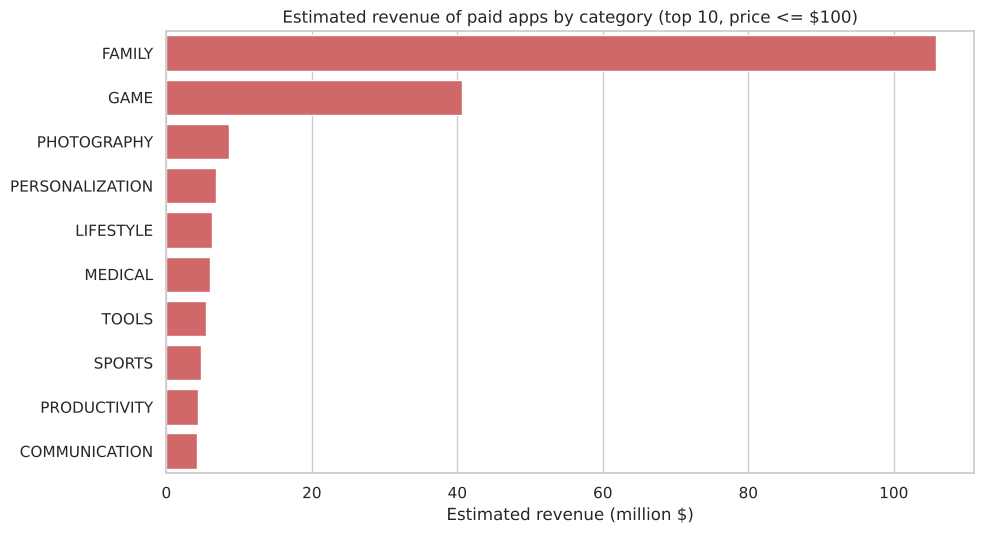

Category
FAMILY             105.7
GAME                40.7
PHOTOGRAPHY          8.5
PERSONALIZATION      6.8
LIFESTYLE            6.2
MEDICAL              6.0
TOOLS                5.5
SPORTS               4.7
PRODUCTIVITY         4.3
COMMUNICATION        4.2
Name: Revenue_Est, dtype: float64

In [24]:
paid_real = apps[(apps["Type"] == "Paid") & (apps["Price"] <= 100)]

rev_cat = (paid_real.groupby("Category")["Revenue_Est"].sum()
           .sort_values(ascending=False).head(10))

plt.figure(figsize=(10, 5.5))
sns.barplot(x=rev_cat.values / 1e6, y=rev_cat.index, color="#e15759")
plt.title("Estimated revenue of paid apps by category (top 10, price <= $100)")
plt.xlabel("Estimated revenue (million $)")
plt.ylabel("")
plt.tight_layout()
plt.show()

total_rev = paid_real["Revenue_Est"].sum()
print(f"Total estimated revenue of paid apps (price <= $100): ${total_rev / 1e6:,.1f} million")
(rev_cat / 1e6).round(1)

In [25]:
paid_rev = paid_real["Revenue_Est"].sort_values(ascending=False)
print(f"Top 10 paid apps make up {paid_rev.head(10).sum() / paid_rev.sum():.1%} of the estimated revenue")
print(f"Top 3 categories make up {rev_cat.head(3).sum() / paid_rev.sum():.1%}")
print(f"Paid apps with fewer than 1,000 installs: {(paid_real['Installs'] < 1000).mean():.1%}")
print(f"Median estimated revenue of a paid app: ${paid_real['Revenue_Est'].median():,.0f}")

Top 10 paid apps make up 56.6% of the estimated revenue
Top 3 categories make up 75.7%
Paid apps with fewer than 1,000 installs: 37.3%
Median estimated revenue of a paid app: $4,950

**Insights**
- Without the novelty apps, estimated paid revenue is about **$205M**, and it is very concentrated: **FAMILY ($105.7M) and GAME ($40.7M)** lead by a long way, followed by PHOTOGRAPHY, PERSONALIZATION and LIFESTYLE (all under $9M).
- A big part of FAMILY is one app: Minecraft alone is roughly two thirds of that category's estimate.
- The **top 10 paid apps make up ~57% of the revenue** and the top three categories ~76%. At the other end, **37% of paid apps have fewer than 1,000 installs** and the median paid app is estimated at only about $5,000. In other words, paid is a hit-driven business: a few winners and a long tail that earns very little.

## 7. Interactive visualisations (plotly)
Two interactive charts: hover to see details, zoom, or click legend items to hide a group.

In [ ]:
import plotly.express as px

# Interactive 1: where do the installs live? Box size = total installs, colour = average rating.
tree_df = cat_summary.reset_index()
fig = px.treemap(tree_df, path=["Category"], values="total_installs",
                 color="avg_rating", color_continuous_scale="RdYlGn",
                 title="Total installs by category (colour = average rating)")
fig.update_layout(margin=dict(t=50, l=10, r=10, b=10))
fig.show()

In [ ]:
# Interactive 2: size vs installs. Hover over a dot to see which app it is, zoom into any region.
fig = px.scatter(size_df, x="Size_MB", y="Installs", color="Type",
                 hover_name="App", hover_data=["Category", "Rating", "Price"],
                 log_y=True, opacity=0.5,
                 title="App size vs installs (hover for app details)")
fig.update_layout(xaxis_title="Size (MB)", yaxis_title="Installs (log scale)")
fig.show()

**What to look for**
- **Treemap:** the biggest boxes by total installs are GAME, COMMUNICATION and TOOLS. Colour shows average rating, so you can spot a big category with weaker ratings (TOOLS is one) versus a smaller one with strong ratings.
- **Scatter:** hover over the dots at the top right to see which apps they are – these are the household names. The paid apps (second colour) sit mostly in the lower part of the chart, which matches the install numbers in section 6.

## 8. Sentiment analysis of user reviews
**Method.** I use **VADER**, a rule-based sentiment tool built for short, informal text like app reviews. It needs no training. For every review it returns a *compound* score from −1 to +1, which I turn into labels with the thresholds the VADER authors suggest:
- score ≥ 0.05 → **positive**
- score ≤ −0.05 → **negative**
- in between → **neutral**

**Setup notes.** The reviews file is loaded separately from the apps file. Reviews without text are removed because there is nothing to score, and the review table is joined to the cleaned apps table through the app name to get each app's category. If the reviews file is not next to the notebook, the cell below says so and the rest of the section is skipped instead of failing.

In [ ]:
import os
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

reviews_file = "googleplaystore_user_reviews.csv"

if os.path.exists(reviews_file):
    reviews_raw = pd.read_csv(reviews_file)
    HAS_REVIEWS = True
    print("Shape:", reviews_raw.shape)
    display(reviews_raw.head())
else:
    reviews_raw = None
    HAS_REVIEWS = False
    print(f"'{reviews_file}' was not found next to this notebook.")
    print("Put the user reviews CSV in the same folder and re-run from this cell - the rest of the sentiment section will then run by itself.")

In [ ]:
if HAS_REVIEWS:
    print("Missing values per column:")
    print(reviews_raw.isnull().sum().to_string())

    # Many rows have no review text at all - there is nothing to score there
    reviews = reviews_raw.dropna(subset=["Translated_Review"]).copy()
    reviews = reviews[reviews["Translated_Review"].str.strip() != ""]
    reviews = reviews.drop_duplicates(subset=["App", "Translated_Review"])

    print(f"\nReviews with text after cleaning: {len(reviews):,} (from {len(reviews_raw):,})")
    print("Apps covered:", reviews["App"].nunique())

In [ ]:
if HAS_REVIEWS:
    analyzer = SentimentIntensityAnalyzer()

    # compound score runs from -1 (very negative) to +1 (very positive)
    reviews["compound"] = reviews["Translated_Review"].astype(str).apply(
        lambda text: analyzer.polarity_scores(text)["compound"])

    # thresholds suggested by the VADER authors
    def label_sentiment(score):
        if score >= 0.05:
            return "positive"
        elif score <= -0.05:
            return "negative"
        return "neutral"

    reviews["vader_sentiment"] = reviews["compound"].apply(label_sentiment)

    shares = (reviews["vader_sentiment"].value_counts(normalize=True) * 100).round(1)
    print("Share of reviews by VADER sentiment (%):")
    print(shares.to_string())

In [ ]:
if HAS_REVIEWS:
    order = ["positive", "neutral", "negative"]
    colors = {"positive": "#59a14f", "neutral": "#bab0ac", "negative": "#e15759"}

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    sns.countplot(data=reviews, x="vader_sentiment", order=order,
                  palette=colors, ax=axes[0])
    axes[0].set_title("Review sentiment (VADER)")
    axes[0].set_xlabel("")
    axes[0].set_ylabel("Number of reviews")

    sns.histplot(reviews["compound"], bins=40, ax=axes[1], color="#4c78a8")
    axes[1].set_title("Distribution of VADER compound score")
    axes[1].set_xlabel("Compound score")
    plt.tight_layout()
    plt.show()

    # Sanity check: the dataset already ships with its own sentiment label
    if "Sentiment" in reviews.columns:
        agree = (reviews["Sentiment"].astype(str).str.lower() == reviews["vader_sentiment"]).mean()
        print(f"Agreement between VADER and the label in the file: {agree:.1%}")
        print(pd.crosstab(reviews["Sentiment"], reviews["vader_sentiment"]))

### 8.1 Sentiment by category
Categories with fewer than 100 reviews are left out because percentages on a handful of reviews are not reliable.

In [ ]:
if HAS_REVIEWS:
    # Attach the app category from the cleaned apps table
    merged = reviews.merge(apps[["App", "Category"]], on="App", how="inner")
    print(f"{len(merged):,} of {len(reviews):,} reviews matched an app in the cleaned apps table")

    counts = pd.crosstab(merged["Category"], merged["vader_sentiment"])
    counts = counts.reindex(columns=["positive", "neutral", "negative"], fill_value=0)

    # Ignore categories with very few reviews - percentages on 20 reviews are not reliable
    counts = counts[counts.sum(axis=1) >= 100]
    sent_pct = counts.div(counts.sum(axis=1), axis=0) * 100
    sent_pct = sent_pct.sort_values("positive", ascending=False)

    sent_pct.plot(kind="barh", stacked=True, figsize=(10, 9),
                  color=["#59a14f", "#bab0ac", "#e15759"])
    plt.gca().invert_yaxis()
    plt.title("Sentiment mix by category (% of reviews)")
    plt.xlabel("% of reviews")
    plt.ylabel("")
    plt.legend(title="Sentiment", bbox_to_anchor=(1.01, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

    print("Most positive categories:")
    print(sent_pct["positive"].head(3).round(1).to_string())
    print("\nMost negative categories (share of negative reviews):")
    print(sent_pct["negative"].sort_values(ascending=False).head(3).round(1).to_string())

In [ ]:
if HAS_REVIEWS:
    # Interactive 3: same chart, but you can hover for exact percentages
    plot_df = sent_pct.reset_index().melt(id_vars="Category", var_name="Sentiment", value_name="Percent")
    fig = px.bar(plot_df, x="Percent", y="Category", color="Sentiment", orientation="h",
                 color_discrete_map={"positive": "#59a14f", "neutral": "#bab0ac", "negative": "#e15759"},
                 category_orders={"Category": list(sent_pct.index[::-1])},
                 title="Sentiment mix by category (hover for exact %)")
    fig.update_layout(height=750)
    fig.show()

**Reading guide for this section**
- VADER works on the words of a review, so sarcasm ("great, it crashes every day") and mixed reviews can be mislabelled. That is why the notebook compares it with the label that ships in the data file where available – the agreement figure shows how far the tool can be trusted.
- A category with a high share of negative reviews is not necessarily a bad market: apps people depend on (banking, navigation) tend to attract complaints when something breaks.

## 9. Conclusion – three insights for a developer launching a new app

**1. Choose the category by demand, not by how popular it looks.**
Business and Medical are crowded yet the typical app there gets only about 1,000 installs. At the other end, categories like **Education, Photography, Shopping, Video Players and Game** have a median of 1 million installs. Education is especially interesting: high median installs *and* one of the best average ratings (4.35). Games have the biggest audience but are winner-takes-most (mean installs 14M against a median of 1M), so they are a high-risk, high-reward choice.

**2. Launch free; charge only if you have a clear reason.**
92% of apps are free and they have a median of 100,000 installs against 1,000 for paid ones. Paid revenue is concentrated in a few hits (the top 10 earn ~57%), 37% of paid apps have under 1,000 installs and the median paid app is estimated at only ≈ $5,000. If you do charge, the $3–5 range had the best median installs. One limit: this dataset does not show ad or in-app-purchase income, which is where most free apps make money.

**3. Aim higher than 4.0 for ratings.**
Ratings are inflated: the median is 4.3 and a 4.0 is only the 25th percentile. A 4.0 app is in the bottom quarter, so plan for 4.3–4.5. Expect a tougher crowd in Dating (3.98), Tools and Maps (both 4.04), where users rate lower than in Events, Art & Design or Education. And the most successful apps tend to be larger (richer in content), so invest in substance, not just a light app.

### Limitations
- Install counts are buckets (lower bounds), so revenue and install comparisons are approximate.
- The data is a snapshot (updates between {FIRST} and {LAST}), and the store has changed since.
- Revenue covers upfront price only. Rating analysis covers only apps that have ratings.
- Correlations here (e.g. size and installs) do not prove cause and effect.

---
*Notebook by saurabhshukla (saurabhshuklant@gmail.com)*